# **Link to Dataset**

[Plant Village Dataset](https://www.kaggle.com/datasets/emmarex/plantdisease/*data*)

# **KNN Classification**

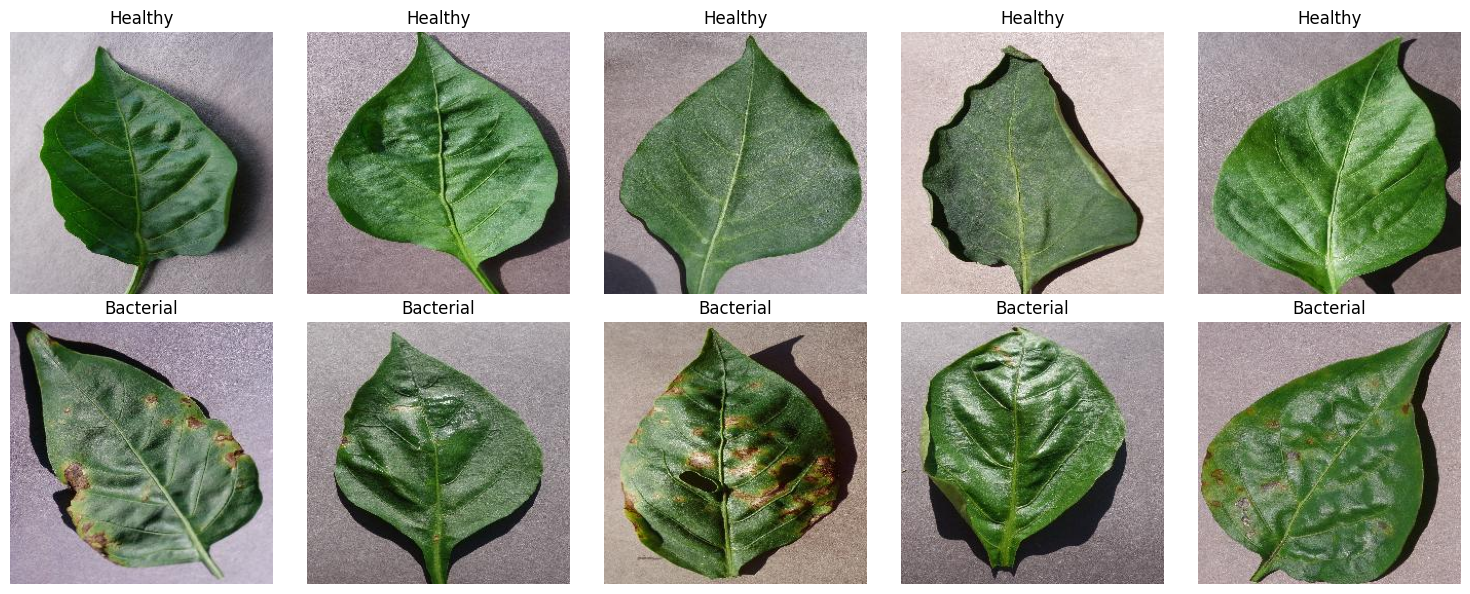

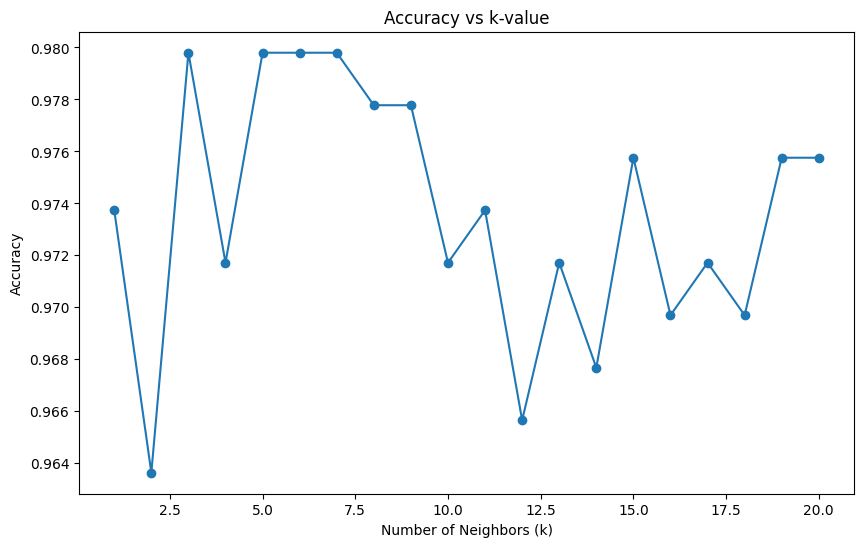

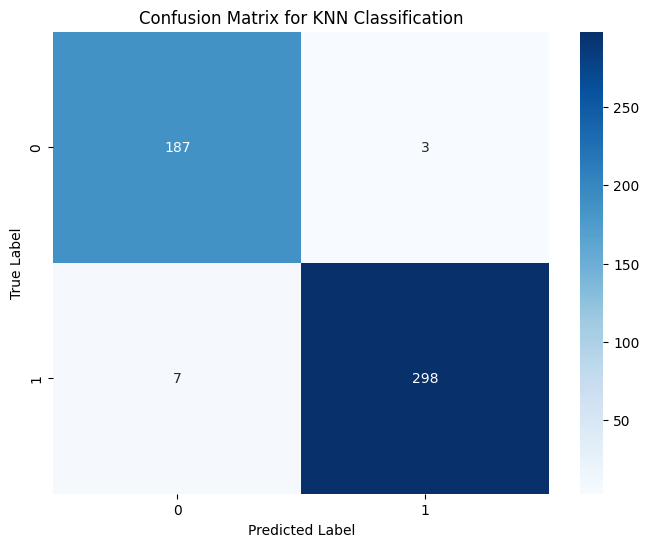

Accuracy: 97.58%
Optimal k: 3
Confusion Matrix:
[[187   3]
 [  7 298]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       190
           1       0.99      0.98      0.98       305

    accuracy                           0.98       495
   macro avg       0.98      0.98      0.98       495
weighted avg       0.98      0.98      0.98       495



In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load your dataset
data = pd.read_csv('/content/drive/MyDrive/combined_image_features.csv')
healthy_image_paths =      ['/content/drive/MyDrive/0a3f2927-4410-46a3-bfda-5f4769a5aaf8___JR_HL 8275.JPG',
                           '/content/drive/MyDrive/0ade14b6-8937-43ea-93eb-98343af6bae7___JR_HL 8026.JPG',
                           '/content/drive/MyDrive/0b76f650-27cf-4b62-b3ad-c97d81e0db0c___JR_HL 8554.JPG',
                           '/content/drive/MyDrive/0b796b7a-dfc8-47f7-9970-8373263c6408___JR_HL 5948.JPG',
                           '/content/drive/MyDrive/0ba474dd-0cfd-4fd2-a58c-8e3d18dbe7c3___JR_HL 8395.JPG']
bacterial_image_paths =    ['/content/drive/MyDrive/00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Spot 3132.JPG',
                             '/content/drive/MyDrive/0a0dbf1f-1131-496f-b337-169ec6693e6f___NREC_B.Spot 9241.JPG',
                             '/content/drive/MyDrive/0a4c007d-41ab-4659-99cb-8a4ae4d07a55___NREC_B.Spot 1954.JPG',
                             '/content/drive/MyDrive/0a9cfb27-280e-475a-bbb4-8eeaeff38b8c___NREC_B.Spot 9177.JPG',
                             '/content/drive/MyDrive/0abffc81-6be8-4b17-a83c-4d2830e30382___JR_B.Spot 9076.JPG']


fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Display healthy images
for i, img_path in enumerate(healthy_image_paths):
    img = mpimg.imread(img_path)
    axes[0, i].imshow(img)
    axes[0, i].set_title('Healthy')
    axes[0, i].axis('off')

# Display bacterial images
for i, img_path in enumerate(bacterial_image_paths):
    img = mpimg.imread(img_path)
    axes[1, i].imshow(img)
    axes[1, i].set_title('Bacterial')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()
# Preprocess the data
# Encode target variable if it is categorical
target_column = 'target'
features = data.drop([target_column, 'image_name'], axis=1)
labels = data[target_column]

# Encode target labels if necessary
label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(labels)

# Scale features
scaler = StandardScaler()
features = scaler.fit_transform(features)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

# Train the KNN model
k_values = range(1, 21)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracy = knn.score(X_test, y_test)
    accuracies.append(accuracy)

# Plot accuracy vs k-values
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o')
plt.title('Accuracy vs k-value')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.show()

# Select the optimal k and evaluate
optimal_k = k_values[np.argmax(accuracies)]
knn = KNeighborsClassifier(n_neighbors=optimal_k)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

# Get the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix for KNN Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Evaluate the model
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Optimal k: {optimal_k}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")

# Get unique labels in y_test and y_pred
unique_labels = np.unique(np.concatenate((y_test, y_pred)))
unique_labels = unique_labels[unique_labels < len(label_encoder.classes_)]  # Filter out-of-bounds indices

# Get target names for the unique labels
target_names = [str(label_encoder.classes_[label]) for label in unique_labels] # Convert numeric labels to strings

# Now pass the unique target names to classification_report
print(classification_report(y_test, y_pred, target_names=target_names))

# **Naive Bayes Classification**

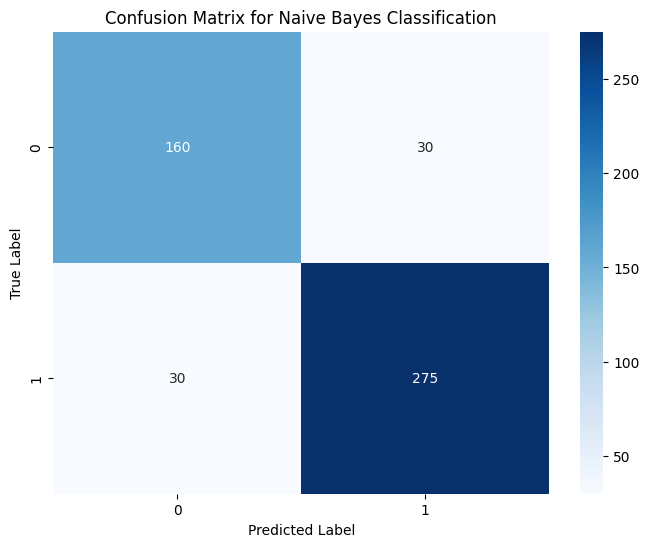

Accuracy: 87.88%
Accuracy: 0.8787878787878788

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.84      0.84       190
           1       0.90      0.90      0.90       305

    accuracy                           0.88       495
   macro avg       0.87      0.87      0.87       495
weighted avg       0.88      0.88      0.88       495



In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
# Initialize the Naive Bayes classifier
model = GaussianNB()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Get the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix for Naive Bayes Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# **SVM Classification**

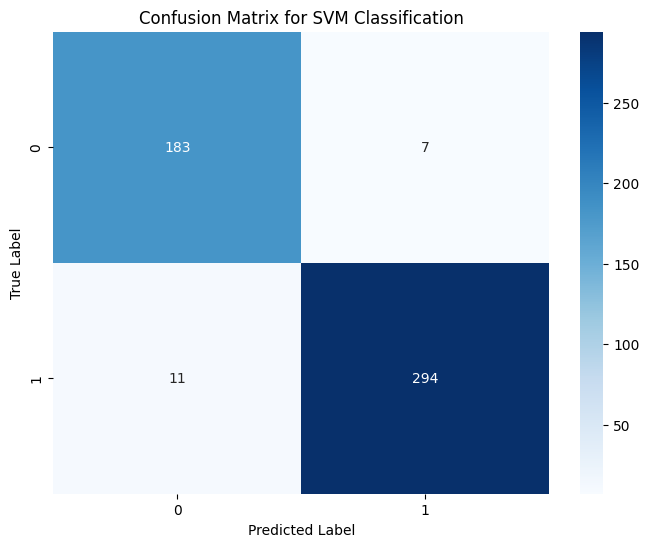

Accuracy: 96.36%
Accuracy: 0.9636363636363636

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.96      0.95       190
           1       0.98      0.96      0.97       305

    accuracy                           0.96       495
   macro avg       0.96      0.96      0.96       495
weighted avg       0.96      0.96      0.96       495



In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
# Initialize the SVM classifier
svm_classifier = SVC(kernel='linear', random_state=42)  # You can use other kernels like 'rbf', 'poly', etc.

# Train the classifier
svm_classifier.fit(X_train, y_train)

# Make predictions on the test set
y_pred = svm_classifier.predict(X_test)

# Get the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix for SVM Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Evaluate the classifier
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# **Logistic Regression Classification**

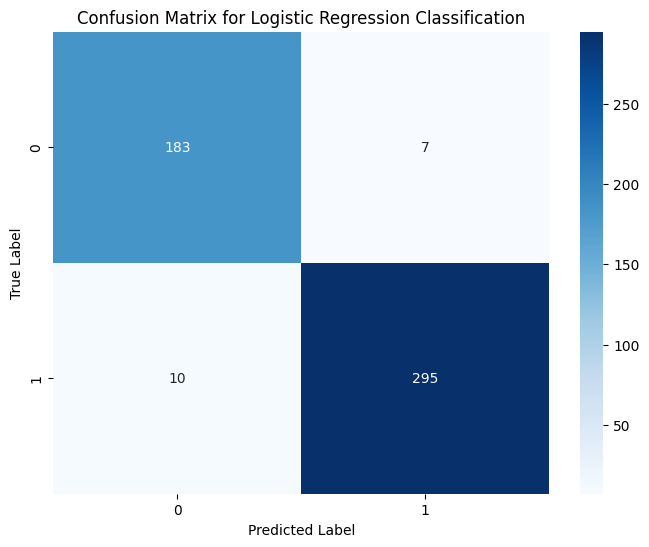

Accuracy: 96.57%
Accuracy: 0.9656565656565657
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96       190
           1       0.98      0.97      0.97       305

    accuracy                           0.97       495
   macro avg       0.96      0.97      0.96       495
weighted avg       0.97      0.97      0.97       495



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
# Initialize the Logistic Regression model
model = LogisticRegression()

# Train the model on the training data
model.fit(X_train, y_train)

# Make predictions on the testing data
y_pred = model.predict(X_test)

# Get the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix for Logistic Regression Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# **Decision Tree Classification**

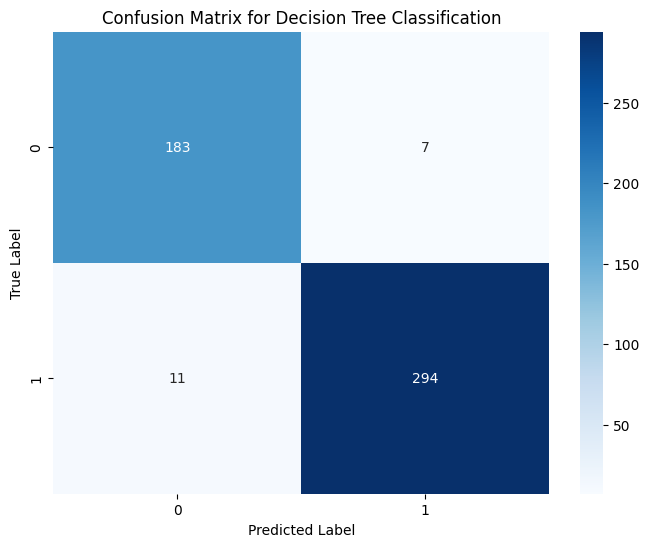

Accuracy: 96.36%

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       190
           1       0.98      0.96      0.97       305

    accuracy                           0.96       495
   macro avg       0.96      0.96      0.96       495
weighted avg       0.96      0.96      0.96       495



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
# Initialize and train the Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = clf.predict(X_test)

# Get the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix for Decision Tree Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# **Ensemble**

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.metrics import accuracy_score, classification_report
# Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
rf_y_pred = rf_classifier.predict(X_test)

print(f"Accuracy: {accuracy * 100:.2f}%")
print("Random Forest Accuracy:", accuracy_score(y_test, rf_y_pred))
print("\nRandom Forest Classification Report:\n", classification_report(y_test, rf_y_pred))


# Gradient Boosting Classifier
gb_classifier = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb_classifier.fit(X_train, y_train)
gb_y_pred = gb_classifier.predict(X_test)

print(f"Accuracy: {accuracy * 100:.2f}%")
print("Gradient Boosting Accuracy:", accuracy_score(y_test, gb_y_pred))
print("\nGradient Boosting Classification Report:\n", classification_report(y_test, gb_y_pred))

# Bagging Classifier
bagging_classifier = BaggingClassifier(n_estimators=100, random_state=42)
bagging_classifier.fit(X_train, y_train)
bagging_y_pred = bagging_classifier.predict(X_test)

print(f"Accuracy: {accuracy * 100:.2f}%")
print("Bagging Classifier Accuracy:", accuracy_score(y_test, bagging_y_pred))
print("\nBagging Classifier Classification Report:\n", classification_report(y_test, bagging_y_pred))

Accuracy: 96.36%
Random Forest Accuracy: 0.9858585858585859

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98       190
           1       0.99      0.99      0.99       305

    accuracy                           0.99       495
   macro avg       0.98      0.99      0.99       495
weighted avg       0.99      0.99      0.99       495

Accuracy: 96.36%
Gradient Boosting Accuracy: 0.9858585858585859

Gradient Boosting Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98       190
           1       0.99      0.99      0.99       305

    accuracy                           0.99       495
   macro avg       0.98      0.99      0.99       495
weighted avg       0.99      0.99      0.99       495

Accuracy: 96.36%
Bagging Classifier Accuracy: 0.9777777777777777

Bagging Classifier Classification Report:
               precision    reca

# **LightGBM**

In [ ]:
import lightgbm as lgb
# Create a LightGBM dataset
train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)
# Set parameters for LightGBM
params = {
    'objective': 'binary',  # For binary classification. Use 'multiclass' for multi-class tasks.
    'metric': 'binary_logloss',  # Metric for evaluation
    'boosting_type': 'gbdt',  # Gradient Boosting Decision Tree
    'learning_rate': 0.1,
    'num_leaves': 31,  # Controls the complexity of the model
    'verbose': -1
}

# Train the LightGBM model
lgb_model = lgb.train(
    params,
    train_data,
    num_boost_round=100,
    valid_sets=[test_data], # Pass validation data here
    callbacks=[lgb.early_stopping(stopping_rounds=10)] # Use early_stopping callback
)

# Make predictions
y_pred = lgb_model.predict(X_test)
# Convert probabilities to binary predictions
y_pred_binary = [1 if prob > 0.5 else 0 for prob in y_pred]

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred_binary)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("Accuracy:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred_binary))

/usr/local/lib/python3.11/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[83]	valid_0's binary_logloss: 0.0410349
Accuracy: 98.79%
Accuracy: 0.9878787878787879

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98       190
           1       0.99      0.99      0.99       305

    accuracy                           0.99       495
   macro avg       0.99      0.99      0.99       495
weighted avg       0.99      0.99      0.99       495



# **Comparison of Results**

In [ ]:

results = [
    {
        "Classifier": "KNN",
        "Accuracy (%)": 97.58,
        "Precision (0)": 0.96,
        "Recall (0)": 0.98,
        "F1-Score (0)": 0.97,
        "Precision (1)": 0.99,
        "Recall (1)": 0.98,
        "F1-Score (1)": 0.98
    },
    {
        "Classifier": "Naive Bayes",
        "Accuracy (%)": 87.88,
        "Precision (0)": 0.84,
        "Recall (0)": 0.84,
        "F1-Score (0)": 0.84,
        "Precision (1)": 0.90,
        "Recall (1)": 0.90,
        "F1-Score (1)": 0.90
    },
    {
        "Classifier": "SVM",
        "Accuracy (%)": 96.36,
        "Precision (0)": 0.94,
        "Recall (0)": 0.96,
        "F1-Score (0)": 0.95,
        "Precision (1)": 0.98,
        "Recall (1)": 0.96,
        "F1-Score (1)": 0.97
    },
    {
        "Classifier": "Logistic Regression",
        "Accuracy (%)": 96.57,
        "Precision (0)": 0.95,
        "Recall (0)": 0.96,
        "F1-Score (0)": 0.96,
        "Precision (1)": 0.98,
        "Recall (1)": 0.97,
        "F1-Score (1)": 0.97
    },
    {
        "Classifier": "Decision Tree",
        "Accuracy (%)": 96.36,
        "Precision (0)": 0.94,
        "Recall (0)": 0.96,
        "F1-Score (0)": 0.95,
        "Precision (1)": 0.98,
        "Recall (1)": 0.96,
        "F1-Score (1)": 0.97
    },
    {
        "Classifier": "Random Forest",
        "Accuracy (%)": 98.59,
        "Precision (0)": 0.98,
        "Recall (0)": 0.98,
        "F1-Score (0)": 0.98,
        "Precision (1)": 0.99,
        "Recall (1)": 0.99,
        "F1-Score (1)": 0.99
    },
    {
        "Classifier": "Gradient Boosting",
        "Accuracy (%)": 98.59,
        "Precision (0)": 0.98,
        "Recall (0)": 0.98,
        "F1-Score (0)": 0.98,
        "Precision (1)": 0.99,
        "Recall (1)": 0.99,
        "F1-Score (1)": 0.99
    },
    {
        "Classifier": "Bagging Classifier",
        "Accuracy (%)": 97.78,
        "Precision (0)": 0.95,
        "Recall (0)": 0.99,
        "F1-Score (0)": 0.97,
        "Precision (1)": 0.99,
        "Recall (1)": 0.97,
        "F1-Score (1)": 0.98
    },
    {
        "Classifier": "LightGBM",
        "Accuracy (%)": 98.79,
        "Precision (0)": 0.98,
        "Recall (0)": 0.98,
        "F1-Score (0)": 0.98,
        "Precision (1)": 0.99,
        "Recall (1)": 0.99,
        "F1-Score (1)": 0.99
    }
]

# Creating a DataFrame
comparison_df = pd.DataFrame(results)

# Display the table
print(comparison_df)


            Classifier  Accuracy (%)  Precision (0)  Recall (0)  F1-Score (0)  \
0                  KNN         97.58           0.96        0.98          0.97   
1          Naive Bayes         87.88           0.84        0.84          0.84   
2                  SVM         96.36           0.94        0.96          0.95   
3  Logistic Regression         96.57           0.95        0.96          0.96   
4        Decision Tree         96.36           0.94        0.96          0.95   
5        Random Forest         98.59           0.98        0.98          0.98   
6    Gradient Boosting         98.59           0.98        0.98          0.98   
7   Bagging Classifier         97.78           0.95        0.99          0.97   
8             LightGBM         98.79           0.98        0.98          0.98   

   Precision (1)  Recall (1)  F1-Score (1)  
0           0.99        0.98          0.98  
1           0.90        0.90          0.90  
2           0.98        0.96          0.97  
3        

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Create DataFrame
comparison_df = pd.DataFrame(results)

# Create figure
fig, ax = plt.subplots(figsize=(20, 7))
ax.axis('off')

# Create table
table = ax.table(
    cellText=comparison_df.values,
    colLabels=comparison_df.columns,
    cellLoc='center',
    loc='center'
)

# Table formatting
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.2)

# Style header
for j in range(len(comparison_df.columns)):
    cell = table[(0, j)]
    cell.set_facecolor('#174A7E')
    cell.set_text_props(color='white', weight='bold')
    cell.set_edgecolor('white')

# Style data rows
for i in range(1, len(comparison_df) + 1):
    for j in range(len(comparison_df.columns)):
        cell = table[(i, j)]
        cell.set_edgecolor('#D6E4F0')

        if i == len(comparison_df):
            # Highlight LightGBM
            cell.set_facecolor('#D9F2E3')
            cell.set_text_props(weight='bold')
        elif i % 2 == 0:
            cell.set_facecolor('#EAF2F8')
        else:
            cell.set_facecolor('white')

# Add title
plt.title(
    'Classifier Performance Comparison',
    fontsize=20,
    fontweight='bold',
    pad=25
)

# Save image
plt.savefig(
    'classifier_comparison.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()